<a href="https://colab.research.google.com/github/arman-hossain45/Convolution-Neural-Network/blob/main/pneumonia_mobilenetv2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pneumonia Detection (Normal vs Opacity) using MobileNetV2 Transfer Learning
Same preprocessing, split ar evaluation VGG16 notebook er moto, jate fair comparison kora jay.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, copy, random
import numpy as np
import torch, torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from torchvision.models import MobileNet_V2_Weights
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, auc)
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# from google.colab import drive
# drive.mount('/content/drive')

train_dir = "/content/drive/MyDrive/Pediatric Chest X-ray Pneumonia/train"
test_dir  = "/content/drive/MyDrive/Pediatric Chest X-ray Pneumonia/test"

Device: cuda


## 1. Preprocessing
Grayscale X-ray -> 3 channel, Resize (224x224), ImageNet normalize. Train-e halka augmentation, flip nei.

In [ ]:
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

## 2. Dataset (train / validation / test)
Same seed (42) ar same split, tai VGG16 er sathe same data-te compare hobe.

In [ ]:
full_train_aug   = datasets.ImageFolder(train_dir, transform=train_tf)
full_train_plain = datasets.ImageFolder(train_dir, transform=eval_tf)
test_dataset     = datasets.ImageFolder(test_dir,  transform=eval_tf)

classes = full_train_aug.classes
print("Classes:", full_train_aug.class_to_idx)

targets = np.array(full_train_aug.targets)
idx_train, idx_val = train_test_split(
    np.arange(len(targets)), test_size=0.15, stratify=targets, random_state=SEED)

train_dataset = Subset(full_train_aug,   idx_train)
val_dataset   = Subset(full_train_plain, idx_val)
print("Train:", len(train_dataset), "| Val:", len(val_dataset), "| Test:", len(test_dataset))

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

counts = np.bincount(targets[idx_train])
print("Train class counts:", dict(zip(classes, counts)))
class_weights = torch.tensor(len(idx_train) / (len(classes) * counts), dtype=torch.float).to(device)

Classes: {'NORMAL': 0, 'PNEUMONIA': 1}
Train: 4455 | Val: 787 | Test: 624
Train class counts: {'NORMAL': np.int64(1147), 'PNEUMONIA': np.int64(3308)}


## 3. MobileNetV2 model
MobileNetV2-er classifier: `Dropout -> Linear(1280, 1000)`. Ekhane amra seta `1280 -> 256 -> 2` diye replace korchi.

`FINE_TUNE_LAST_BLOCKS = True` korle last kichu block-o train hobe (aro bhalo accuracy pete pare).

In [ ]:
mobilenet = models.mobilenet_v2(weights=MobileNet_V2_Weights.DEFAULT)

for p in mobilenet.features.parameters():
    p.requires_grad = False

FINE_TUNE_LAST_BLOCKS = False
if FINE_TUNE_LAST_BLOCKS:
    for p in mobilenet.features[14:].parameters():   # last 4 blocks
        p.requires_grad = True

mobilenet.classifier = nn.Sequential(
    nn.Dropout(0.4),
    nn.Linear(1280, 256),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, 2),
)
mobilenet = mobilenet.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
params = [p for p in mobilenet.parameters() if p.requires_grad]
optimizer = torch.optim.Adam(params, lr=1e-3 if not FINE_TUNE_LAST_BLOCKS else 1e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

print("Trainable params:", sum(p.numel() for p in params))

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 65.7MB/s]

Trainable params: 328450


## 4. Training
Note: MobileNet-e BatchNorm ache. Feature part freeze thakle seta `eval()` mode-e rakhi, jate pretrained BN statistics na noshto hoy.

In [ ]:
def set_mode(train):
    mobilenet.train() if train else mobilenet.eval()
    if train and not FINE_TUNE_LAST_BLOCKS:
        mobilenet.features.eval()          # frozen BN stats fixed thakbe

def run_epoch(loader, train=False):
    set_mode(train)
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = mobilenet(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * y.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)
    return total_loss / total, correct / total

EPOCHS, PATIENCE = 3, 6
best_val, best_state, wait = float("inf"), None, 0
history = {"tr_loss": [], "va_loss": [], "tr_acc": [], "va_acc": []}

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    scheduler.step(va_loss)
    for k, v in zip(history, [tr_loss, va_loss, tr_acc, va_acc]):
        history[k].append(v)
    print(f"Epoch {epoch:02d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f}")
    if va_loss < best_val:
        best_val, best_state, wait = va_loss, copy.deepcopy(mobilenet.state_dict()), 0
        torch.save(best_state, "mobilenetv2_best.pth")
    else:
        wait += 1
        if wait >= PATIENCE:
            print("Early stopping"); break

mobilenet.load_state_dict(best_state)

Epoch 01 | train loss 0.2729 acc 0.8936 | val loss 0.2199 acc 0.8653
Epoch 02 | train loss 0.2160 acc 0.9147 | val loss 0.2281 acc 0.8590
Epoch 03 | train loss 0.2128 acc 0.9174 | val loss 0.1459 acc 0.9543


<All keys matched successfully>

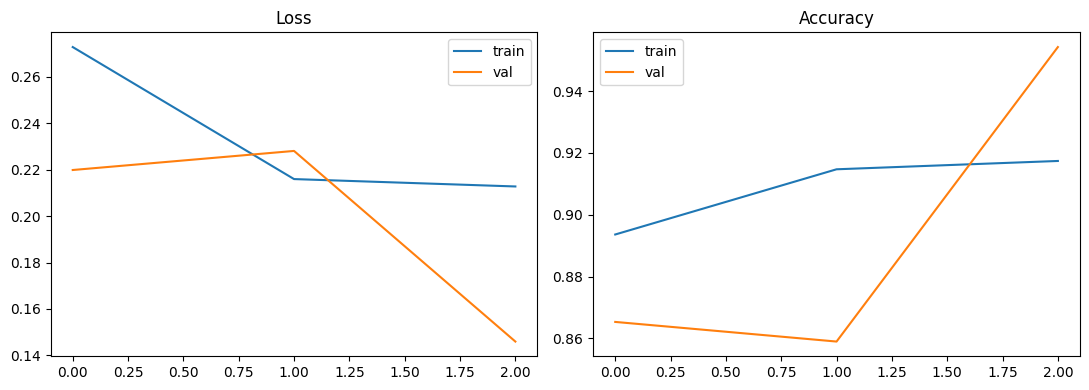

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history["tr_loss"], label="train"); ax[0].plot(history["va_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history["tr_acc"], label="train"); ax[1].plot(history["va_acc"], label="val")
ax[1].set_title("Accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Evaluation on test set

MobileNetV2 Test Accuracy: 83.49%
Sensitivity (Recall, opacity): 0.9692
Specificity (normal):          0.6111
Precision:                     0.8060

              precision    recall  f1-score   support

      NORMAL     0.9226    0.6111    0.7352       234
   PNEUMONIA     0.8060    0.9692    0.8801       390

    accuracy                         0.8349       624
   macro avg     0.8643    0.7902    0.8077       624
weighted avg     0.8497    0.8349    0.8258       624

AUC: 0.9502


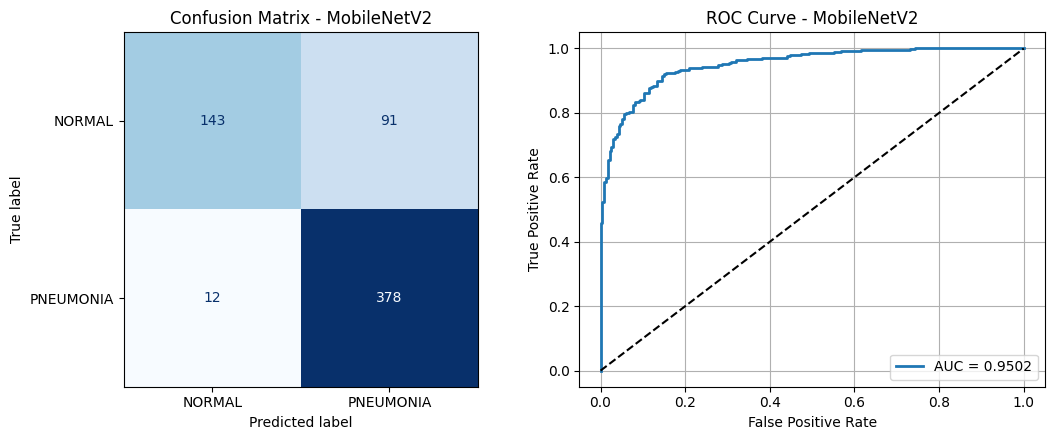

In [ ]:
mobilenet.eval()
all_labels, all_preds, all_probs = [], [], []
with torch.no_grad():
    for x, y in test_loader:
        out = mobilenet(x.to(device))
        prob = torch.softmax(out, 1)[:, 1]
        all_labels += y.numpy().tolist()
        all_preds  += out.argmax(1).cpu().numpy().tolist()
        all_probs  += prob.cpu().numpy().tolist()

all_labels, all_preds, all_probs = map(np.array, (all_labels, all_preds, all_probs))
acc = (all_labels == all_preds).mean()
print(f"MobileNetV2 Test Accuracy: {acc*100:.2f}%")

cm = confusion_matrix(all_labels, all_preds)
tn, fp, fn, tp = cm.ravel()
print(f"Sensitivity (Recall, opacity): {tp/(tp+fn):.4f}")
print(f"Specificity (normal):          {tn/(tn+fp):.4f}")
print(f"Precision:                     {tp/(tp+fp):.4f}")
print()
print(classification_report(all_labels, all_preds, target_names=classes, digits=4))

fpr, tpr, _ = roc_curve(all_labels, all_probs)
roc_auc = auc(fpr, tpr)
print(f"AUC: {roc_auc:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion Matrix - MobileNetV2")
ax[1].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc:.4f}")
ax[1].plot([0, 1], [0, 1], "k--")
ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate")
ax[1].set_title("ROC Curve - MobileNetV2"); ax[1].legend(); ax[1].grid(True)
plt.tight_layout(); plt.show()

## 6. Model size and speed (MobileNet-er main advantage)
Thesis-e VGG16 vs MobileNetV2 comparison table-e ei number gulo use korte paren.

In [ ]:
import time
total_params = sum(p.numel() for p in mobilenet.parameters())
print(f"Total params: {total_params/1e6:.2f} M")
print(f"Model size:   {os.path.getsize('mobilenetv2_best.pth')/1e6:.1f} MB")

x = torch.randn(1, 3, 224, 224).to(device)
mobilenet.eval()
with torch.no_grad():
    for _ in range(10): mobilenet(x)          # warm-up
    if device.type == "cuda": torch.cuda.synchronize()
    t = time.time()
    for _ in range(100): mobilenet(x)
    if device.type == "cuda": torch.cuda.synchronize()
print(f"Inference time: {(time.time()-t)/100*1000:.2f} ms / image")

Total params: 2.55 M
Model size:   10.5 MB
Inference time: 7.85 ms / image


## 7. Single image prediction

In [ ]:
from PIL import Image

def predict_image(path):
    img = Image.open(path).convert("L")
    x = eval_tf(img).unsqueeze(0).to(device)
    mobilenet.eval()
    with torch.no_grad():
        p = torch.softmax(mobilenet(x), 1)[0].cpu().numpy()
    print({c: f"{p[i]*100:.2f}%" for i, c in enumerate(classes)})
    plt.imshow(img, cmap="gray"); plt.axis("off")
    plt.title(f"Prediction: {classes[p.argmax()]}"); plt.show()

# predict_image("/content/drive/MyDrive/sample_xray.png")

## 8. Grad-CAM

In [ ]:
!pip install -q grad-cam

In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

def show_gradcam(dataset, index=0):
    img_t, label = dataset[index]
    inp = img_t.unsqueeze(0).to(device)
    mobilenet.eval()
    pred = mobilenet(inp).argmax(1).item()
    with GradCAM(model=mobilenet, target_layers=[mobilenet.features[-1]]) as cam:
        g = cam(input_tensor=inp, targets=[ClassifierOutputTarget(pred)])[0]
    rgb = (img_t.permute(1, 2, 0).numpy() * std + mean).clip(0, 1).astype(np.float32)
    vis = show_cam_on_image(rgb, g, use_rgb=True)
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(rgb); ax[0].set_title(f"Actual: {classes[label]}"); ax[0].axis("off")
    ax[1].imshow(vis); ax[1].set_title(f"Grad-CAM (Pred: {classes[pred]})"); ax[1].axis("off")
    plt.show()

show_gradcam(test_dataset, 0)